In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [4]:
df = pd.read_csv("/content/MINI PROJ 1 .csv")

In [5]:
#shape of the dataframe
df.shape

(8148, 13)

In [6]:
#columns
df.columns.tolist()

['Name',
 'year',
 'selling_price',
 'km_driven',
 'fuel',
 'seller_type',
 'transmission',
 'owner',
 'mileage',
 'engine',
 'max_power',
 'torque',
 'seats']

In [7]:
#first 5 rows
df.head()

,Name,year,selling_price,km_driven,fuel,seller_type,transmission,owner,mileage,engine,max_power,torque,seats
0,Maruti Alto 800 LXI Opt,2023,410000,10000,Petrol,Individual,Manual,First Owner,19.03 kmpl,999 CC,71.01bhp,96Nm,5.0
1,Skoda Slavia 1.0 TSI Ambition,2023,1350000,10000,Petrol,Individual,Manual,First Owner,14.08 kmpl,1956 CC,167.67bhp,350nm,5.0
2,BMW 3 Series Gran Limousine 320Ld Luxury Line,2023,5800000,1000,Diesel,Dealer,Automatic,First Owner,18.15 kmpl,998 CC,118.35bhp,172Nm,5.0
3,MG ZS EV Exclusive,2023,2650000,10000,Electric,Dealer,Automatic,First Owner,32.52 kmpl,998 CC,58.33bhp,78Nm,5.0
4,Tata Punch Adventure,2023,715000,10000,Petrol,Individual,Manual,First Owner,12.15 kmpl,1451 CC,141bhp,250Nm,5.0


In [8]:
#last 5 rows
df.tail()

,Name,year,selling_price,km_driven,fuel,seller_type,transmission,owner,mileage,engine,max_power,torque,seats
8143,Ambassador Classic 2000 DSZ AC PS,1994,99000,100000,Diesel,Individual,Manual,Second Owner,12.8 kmpl,1995 CC,52 bhp,106Nm@ 2200rpm,5.0
8144,Mahindra Jeep CL 500 MDI,1994,120000,100000,Diesel,Individual,Manual,Second Owner,NaN,NaN,NaN,NaN,NaN
8145,Maruti 800 AC,1994,45000,60000,Petrol,Individual,Manual,First Owner,16.1 kmpl,796 CC,37 bhp,59Nm@ 2500rpm,4.0
8146,Maruti Omni LPG STD BSIV,1991,55000,120000,LPG,Individual,Manual,Second Owner,NaN,NaN,NaN,NaN,NaN
8147,Mahindra Willys CJ 3B 4X4,1983,300000,10000,Diesel,Individual,Manual,Third Owner,NaN,NaN,NaN,NaN,NaN


In [9]:
#column types
df.dtypes

,0
Name,object
year,int64
selling_price,int64
km_driven,int64
fuel,object
seller_type,object
transmission,object
owner,object
mileage,object
engine,object


In [10]:
#information of dataframe columns
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8148 entries, 0 to 8147
Data columns (total 13 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Name           8148 non-null   object 
 1   year           8148 non-null   int64  
 2   selling_price  8148 non-null   int64  
 3   km_driven      8148 non-null   int64  
 4   fuel           8148 non-null   object 
 5   seller_type    8148 non-null   object 
 6   transmission   8148 non-null   object 
 7   owner          8148 non-null   object 
 8   mileage        7927 non-null   object 
 9   engine         7927 non-null   object 
 10  max_power      7933 non-null   object 
 11  torque         7926 non-null   object 
 12  seats          7927 non-null   float64
dtypes: float64(1), int64(3), object(9)
memory usage: 827.7+ KB


In [11]:
#checking for null values
df.isnull().sum()

,0
Name,0
year,0
selling_price,0
km_driven,0
fuel,0
seller_type,0
transmission,0
owner,0
mileage,221
engine,221


In [12]:
#checking for duplicate values
df.duplicated().sum()

np.int64(1202)

In [13]:
#inconcistent categories
cat_cols = df.select_dtypes(include='object').columns

for col in cat_cols:
    print(f"\n{col}:")
    print(df[col].nunique())


Name:
2076

fuel:
5

seller_type:
3

transmission:
4

owner:
5

mileage:
398

engine:
121

max_power:
331

torque:
449


In [14]:
df.size

105924

In [15]:
# DATA CLEANING
# Remove duplicates
df = df.drop_duplicates()

# Remove leading/trailing spaces
for col in df.select_dtypes(include='object').columns:
    df[col] = df[col].astype(str).str.strip()

# Convert mileage
df['mileage_num'] = (
    df['mileage']
    .astype(str)
    .str.extract('([0-9.]+)')
    .astype(float)
)

# Convert engine
df['engine_num'] = (
    df['engine']
    .astype(str)
    .str.extract('([0-9.]+)')
    .astype(float)
)

# Convert max power
df['max_power_num'] = (
    df['max_power']
    .astype(str)
    .str.extract('([0-9.]+)')
    .astype(float)
)

# Convert seats
df['seats'] = pd.to_numeric(
    df['seats'],
    errors='coerce'
)

# Fill missing numeric values with median
numeric_cols = [
    'mileage_num',
    'engine_num',
    'max_power_num',
    'seats'
]

for col in numeric_cols:
    df[col].fillna(df[col].median(), inplace=True)

print("\nData cleaned successfully")


Data cleaned successfully


/tmp/ipykernel_577/2669574410.py:48: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df[col].fillna(df[col].median(), inplace=True)


In [16]:
df.size

111136

In [17]:
#descriptive statistics for numerical columns
df.describe

<bound method NDFrame.describe of                                                Name  year  selling_price  \
0                           Maruti Alto 800 LXI Opt  2023         410000   
1                     Skoda Slavia 1.0 TSI Ambition  2023        1350000   
2     BMW 3 Series Gran Limousine 320Ld Luxury Line  2023        5800000   
3                                MG ZS EV Exclusive  2023        2650000   
4                              Tata Punch Adventure  2023         715000   
...                                             ...   ...            ...   
8143              Ambassador Classic 2000 DSZ AC PS  1994          99000   
8144                       Mahindra Jeep CL 500 MDI  1994         120000   
8145                                  Maruti 800 AC  1994          45000   
8146                       Maruti Omni LPG STD BSIV  1991          55000   
8147                      Mahindra Willys CJ 3B 4X4  1983         300000   

      km_driven      fuel seller_type transmission         owner     mileage  \
0         10000    Petrol  Individual       Manual   First Owner  19.03 kmpl   
1         10000    Petrol  Individual       Manual   First Owner  14.08 kmpl   
2          1000    Diesel      Dealer    Automatic   First Owner  18.15 kmpl   
3         10000  Electric      Dealer    Automatic   First Owner  32.52 kmpl   
4         10000    Petrol  Individual       Manual   First Owner  12.15 kmpl   
...         ...       ...         ...          ...           ...         ...   
8143     100000    Diesel  Individual       Manual  Second Owner   12.8 kmpl   
8144     100000    Diesel  Individual       Manual  Second Owner         nan   
8145      60000    Petrol  Individual       Manual   First Owner   16.1 kmpl   
8146     120000       LPG  Individual       Manual  Second Owner         nan   
8147      10000    Diesel  Individual       Manual   Third Owner         nan   

       engine  max_power          torque  seats  mileage_num  engine_num  \
0      999 CC   71.01bhp            96Nm    5.0        19.03       999.0   
1     1956 CC  167.67bhp           350nm    5.0        14.08      1956.0   
2      998 CC  118.35bhp           172Nm    5.0        18.15       998.0   
3      998 CC   58.33bhp            78Nm    5.0        32.52       998.0   
4     1451 CC     141bhp           250Nm    5.0        12.15      1451.0   
...       ...        ...             ...    ...          ...         ...   
8143  1995 CC     52 bhp  106Nm@ 2200rpm    5.0        12.80      1995.0   
8144      nan        nan             nan    5.0        19.40      1248.0   
8145   796 CC     37 bhp   59Nm@ 2500rpm    4.0        16.10       796.0   
8146      nan        nan             nan    5.0        19.40      1248.0   
8147      nan        nan             nan    5.0        19.40      1248.0   

      max_power_num  
0             71.01  
1            167.67  
2            118.35  
3             58.33  
4            141.00  
...             ...  
8143          52.00  
8144          81.83  
8145          37.00  
8146          81.83  
8147          81.83  

[6946 rows x 16 columns]>

In [18]:
#descriptive statistics for objective columns
df.describe(include='object')

,Name,fuel,seller_type,transmission,owner,mileage,engine,max_power,torque
count,6946,6946,6946,6946,6946,6946,6946,6946,6946
unique,2074,5,3,2,5,399,122,332,449
top,Maruti Swift Dzire VDI,Diesel,Individual,Manual,First Owner,18.9 kmpl,1248 CC,74 bhp,190Nm@ 2000rpm
freq,118,3760,6232,6355,4259,210,907,324,472


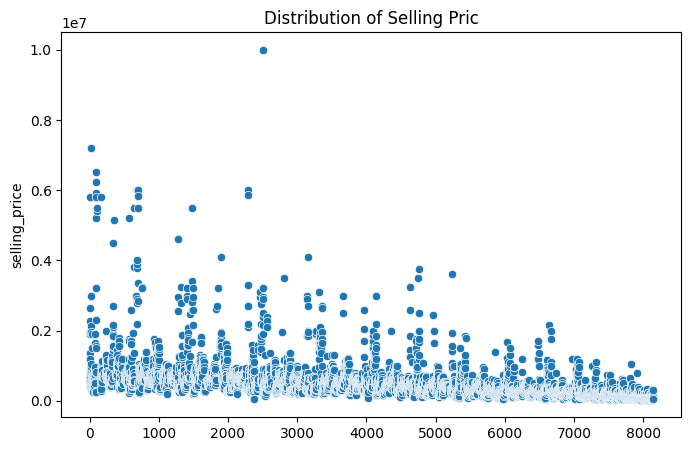

In [19]:
#UNIVARIATE ANALYSIS
plt.figure(figsize=(8,5))
sns.scatterplot(df['selling_price'])
plt.title('Distribution of Selling Pric')
plt.show()

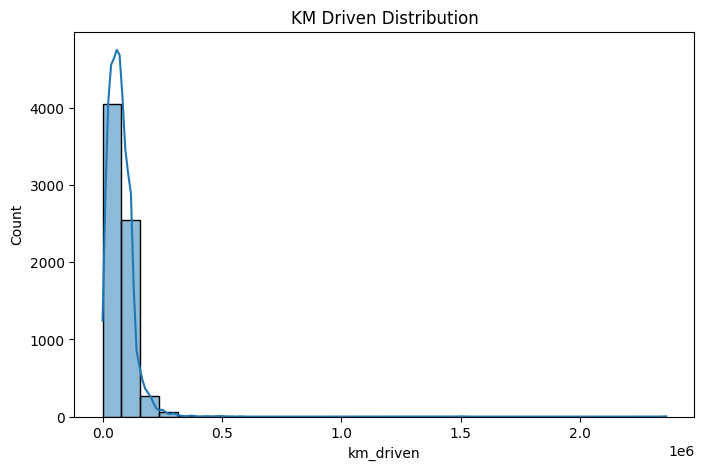

In [20]:
#UNIVARIATE ANALYSIS
plt.figure(figsize=(8,5))
sns.histplot(df['km_driven'], bins=30, kde=True)
plt.title("KM Driven Distribution")
plt.show()

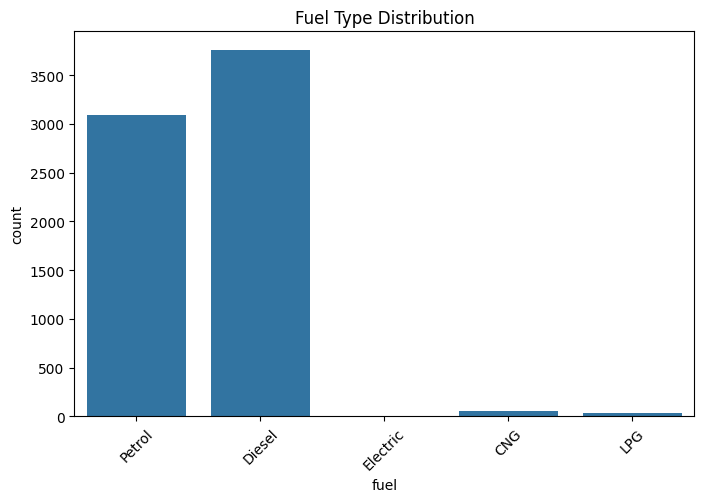

In [21]:
#UNIVARIATE ANALYSIS
plt.figure(figsize=(8,5))
sns.countplot(x='fuel', data=df)
plt.title("Fuel Type Distribution")
plt.xticks(rotation=45)
plt.show()

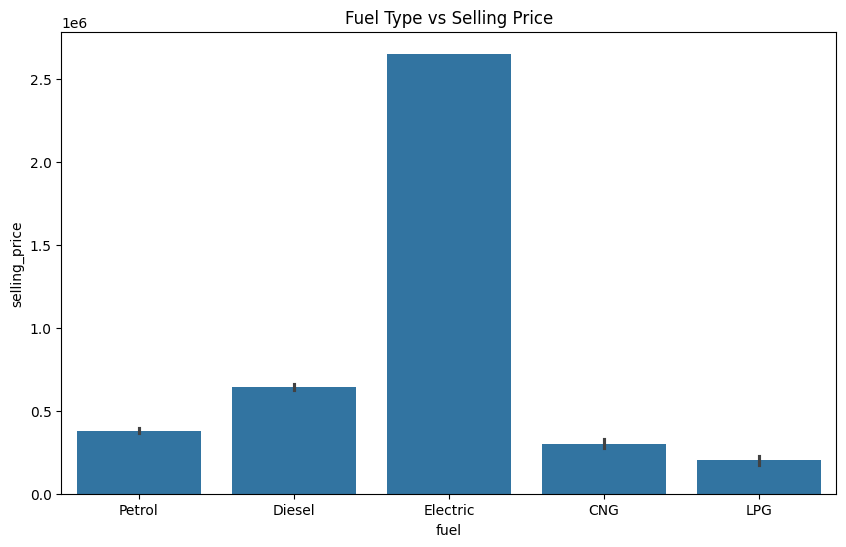

In [22]:
#BIVARIATE ANALYSIS
plt.figure(figsize=(10, 6))
sns.barplot(x='fuel', y='selling_price', data=df)
plt.title('Fuel Type vs Selling Price')
plt.show()

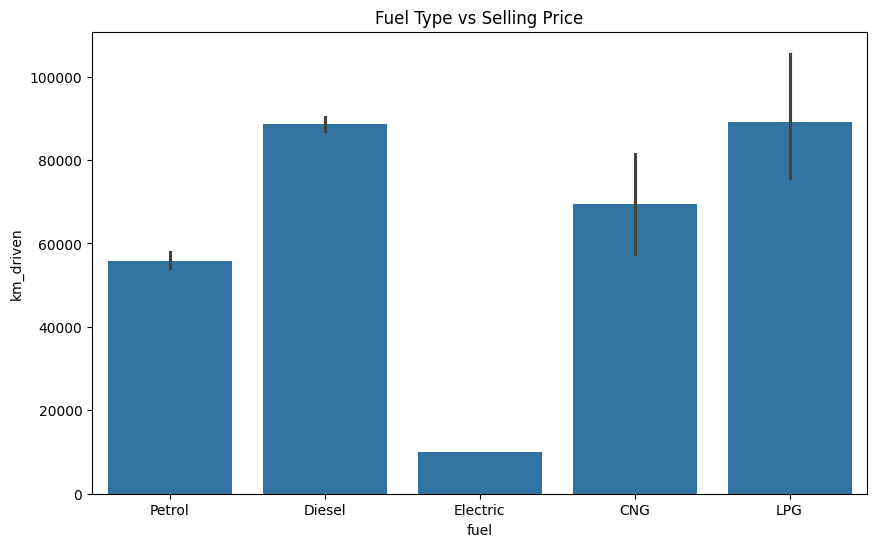

In [23]:
#BIVARIATE ANALYSIS
plt.figure(figsize=(10, 6))
sns.barplot(x='fuel', y='km_driven', data=df)
plt.title('Fuel Type vs Selling Price')
plt.show()

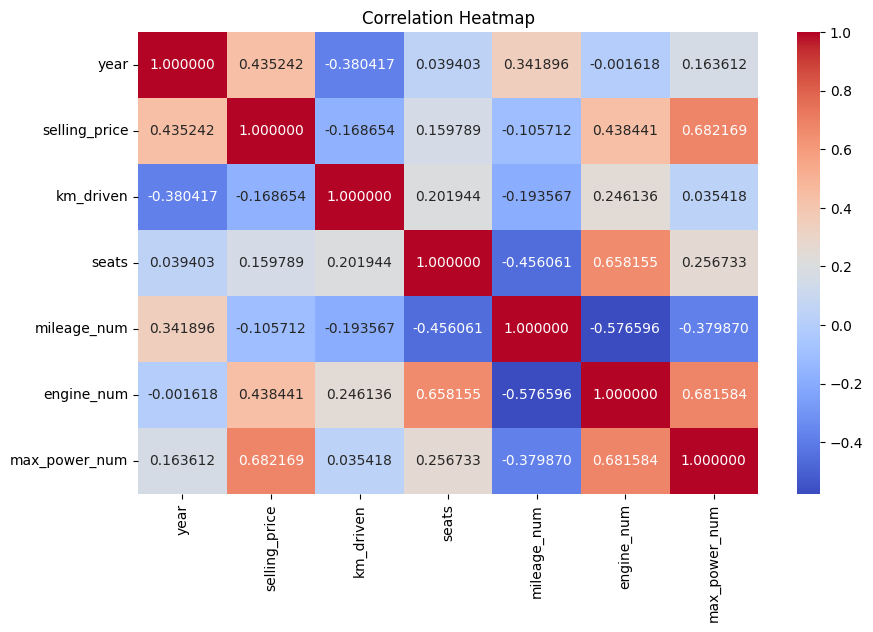

In [24]:
#MULTIVARIATE ANALYSIS
plt.figure(figsize=(10, 6))
sns.heatmap(df.select_dtypes(include='number').corr(), annot=True, cmap='coolwarm', fmt='2f')
plt.title('Correlation Heatmap')
plt.show()

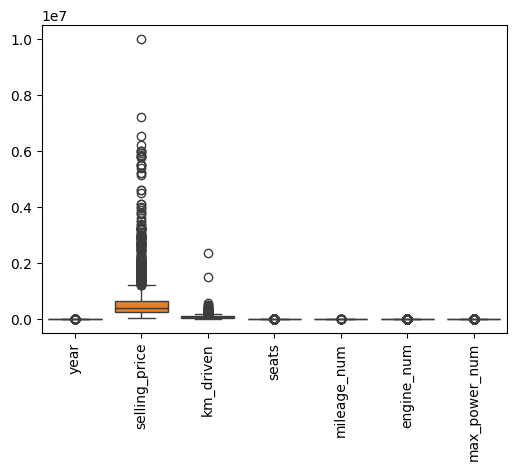

In [25]:
#CHECK OUTLIERS
plt.figure(figsize=(6,4))
sns.boxplot(data=df.select_dtypes(include='number'))
plt.xticks(rotation = 90)
plt.show()

In [26]:
#TOP INSIGHTS
print("""
1. Newer cars generally have higher selling prices.
2. Cars with higher kilometers driven tend to have lower resale value.
3. Engine size and max power often show positive correlation with price.
4. Luxury and premium vehicles create most price outliers.
5. Manual and Automatic transmissions may show different resale trends.
6. Fuel type influences pricing patterns.
7. Most vehicles belong to First Owner category.
8. Duplicate listings can significantly affect statistics and should be removed.
""")


1. Newer cars generally have higher selling prices.
2. Cars with higher kilometers driven tend to have lower resale value.
3. Engine size and max power often show positive correlation with price.
4. Luxury and premium vehicles create most price outliers.
5. Manual and Automatic transmissions may show different resale trends.
6. Fuel type influences pricing patterns.
7. Most vehicles belong to First Owner category.
8. Duplicate listings can significantly affect statistics and should be removed.

